---
title: "Figures: Canonical Asset Pricing and Rational Bubbles"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=Bubbles.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/asset_pricing/Bubbles/Bubbles.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/asset_pricing/Bubbles/Bubbles.ipynb).

In [the bubbles chapter](https://intertemporal-choice.github.io/content/asset-pricing/bubbles), a stock's price is its fundamental value plus a bubble, $\mathsf{P}_{t} = \mathsf{P}_{t}^{*} + B_{t}$, and a risk-neutral investor holds the bubble only if it is expected to grow at the interest factor $\mathsf{R}$. Blanchard's (1979) bubble survives each period with probability $1-\mathsf{D}$ and bursts, to zero, with probability $\mathsf{D}$:

$$
B_{t+1} = \begin{cases} (\mathsf{R}/(1-\mathsf{D}))B_{t} & \text{with probability } 1-\mathsf{D} \\ 0 & \text{with probability } \mathsf{D}, \end{cases}
$$

so it is expected to grow by $\mathsf{R}$, $\mathbb{E}_{t}[B_{t+1}] = \mathsf{R}B_{t}$, and grows faster than that while it lasts. Its lifetime is geometric: it survives $s$ periods with probability $(1-\mathsf{D})^{s}$, lasts $1/\mathsf{D}$ periods on average, and its chance of surviving halves every $\log 2/(-\log(1-\mathsf{D}))$ periods.

In general equilibrium, Tirole (1985) showed that a bubble can last in the [Diamond OLG model](https://intertemporal-choice.github.io/content/consumption/olgmodel) when the economy is dynamically inefficient. The last part of the notebook draws that economy.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from intertemporal_choice import bubbles, style

style.use_book_style()

## Bubbles that burst

`simulate` follows many bubbles, each starting at $B_{0} = 1$, with Blanchard's rule; `expected` is the bubble's expected value, which grows at the interest factor. A bubble's lifetime is the number of periods until it bursts; since each period's draw is independent, it has a geometric distribution, which `lifetimes` samples directly.

In [ ]:
def simulate(R, D, periods, bubbles=12, seed=0):
    """Paths of `bubbles` bubbles, each starting at 1, under Blanchard's rule."""
    rng = np.random.default_rng(seed)
    B = np.ones((periods + 1, bubbles))
    for t in range(periods):
        survives = rng.random(bubbles) >= D
        B[t + 1] = np.where(survives, B[t] * R / (1 - D), 0.0)
    return B


def expected(R, periods):
    return R ** np.arange(periods + 1)  # E_0[B_t] = R^t B_0


def lifetimes(D, bubbles=20_000, seed=1):
    """The periods until each of many bubbles bursts."""
    return np.random.default_rng(seed).geometric(D, size=bubbles)

With a 5 percent chance of bursting each period and an interest factor of 1.04: a dozen bubbles, on a log scale, against their expected value; and the lifetimes of twenty thousand.

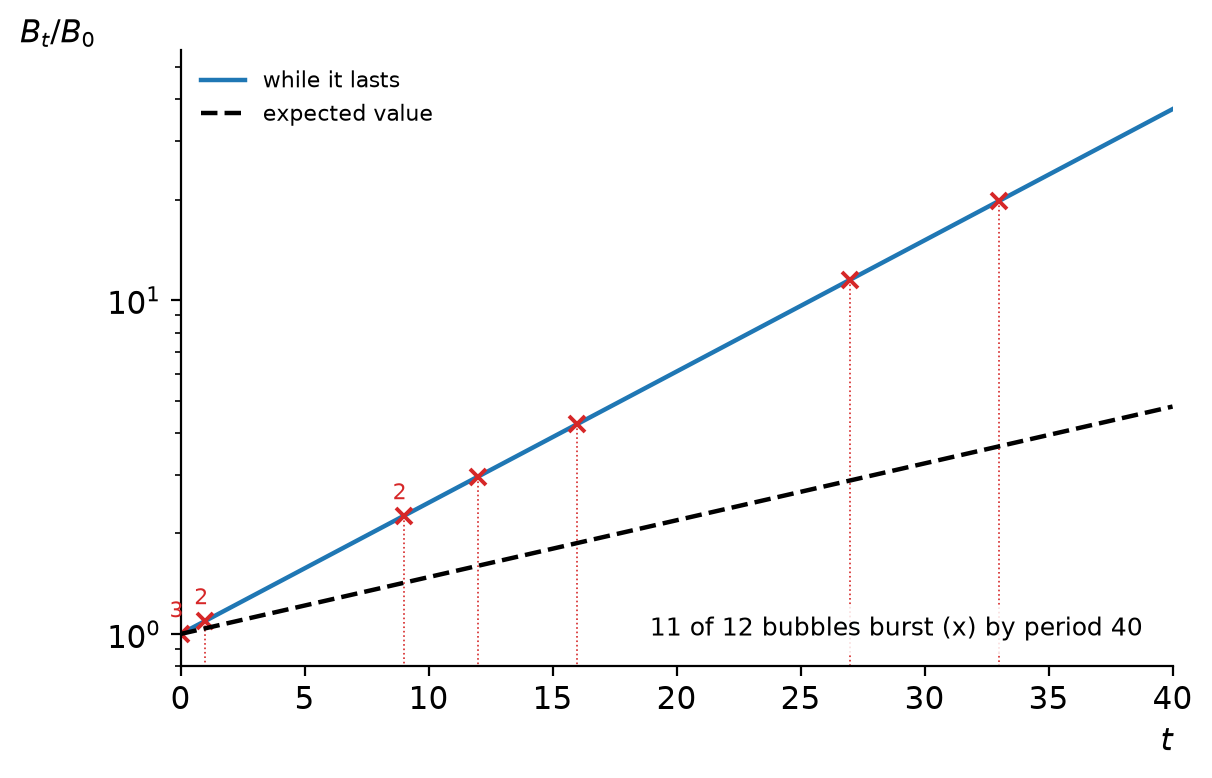

In [ ]:
D, R = 0.05, 1.04
fig, ax = plt.subplots()
bubbles.draw_paths(ax, simulate(R, D, bubbles.PERIODS), expected(R, bubbles.PERIODS))
style.save(fig, "BubblePaths")

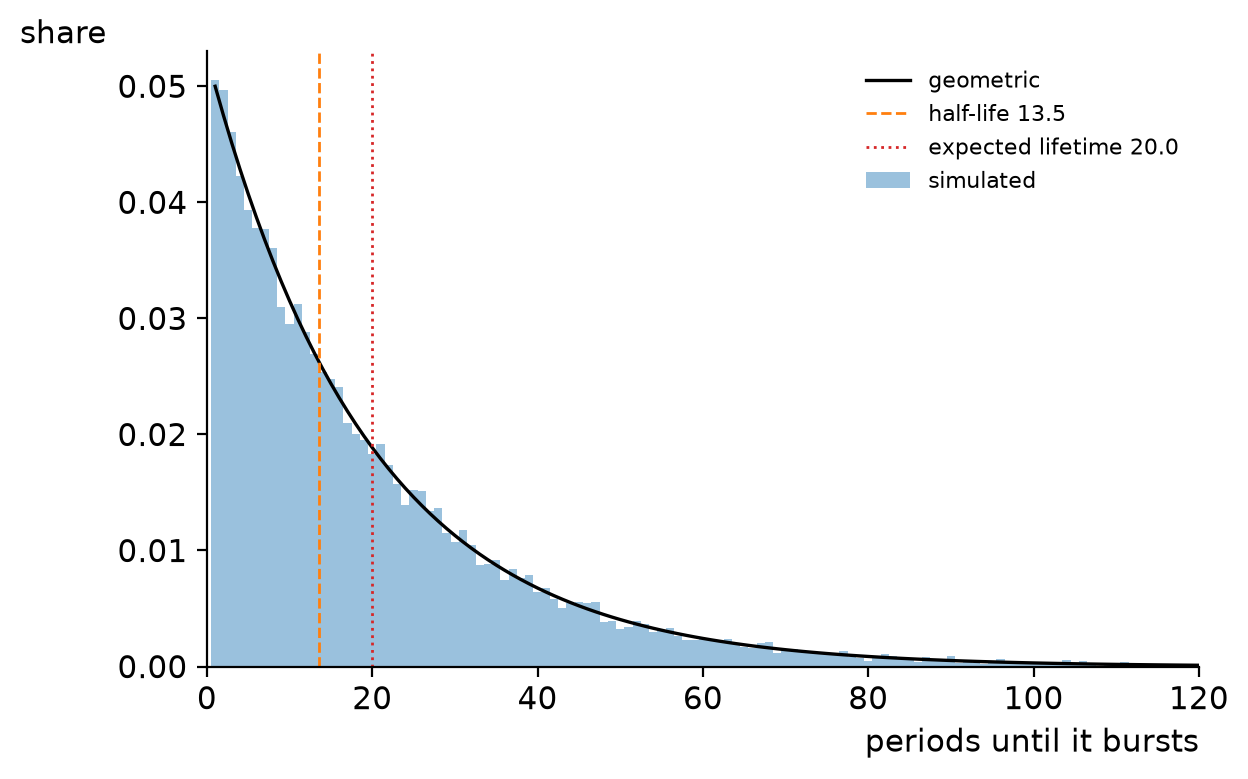

In [ ]:
life = lifetimes(D)
fig, ax = plt.subplots()
bubbles.draw_lifetimes(ax, life, D)
style.save(fig, "BubbleLifetimes")

In [ ]:
print(f"expected lifetime 1/D = {1 / D:.1f} periods; half-life log 2 / (-log(1 - D)) = {np.log(2) / -np.log(1 - D):.2f} periods")
print(f"simulated: mean {np.mean(life):.2f}, median {np.median(life):.0f}; still alive after 13 periods {np.mean(life > 13):.3f}, after 14 {np.mean(life > 14):.3f}")

expected lifetime 1/D = 20.0 periods; half-life log 2 / (-log(1 - D)) = 13.51 periods
simulated: mean 19.95, median 14; still alive after 13 periods 0.513, after 14 0.488


## Tirole's bubble

The economy is the OLG chapter's: the young earn the wage $(1-\alpha)k^{\alpha}$ and save the share $\beta/(1+\beta)$ of it, the population grows by the factor $\Xi$, and capital earns the interest factor $1 + \alpha k^{\alpha-1}$. With no bubble, $k_{t+1} = \mathcal{Q}k_{t}^{\alpha}$ and capital converges to $\bar{k}$. A bubble is an asset the young buy with part of their savings: if each young person holds $b_{t}$ of it, then $\Xi k_{t+1} = \beta w_{t}/(1+\beta) - b_{t}$, and the bubble per young person grows by $\mathsf{R}_{t+1}/\Xi$, since its value is shared among a population growing by $\Xi$. A steady state with a bubble needs $\mathsf{R} = \Xi$: capital at the golden rule, $k^{**}$. Only when $\bar{k} > k^{**}$, so that the interest rate without the bubble is below the growth rate, is there savings left over for the bubble, $b = \Xi(k_{t+1}(k^{**}) - k^{**})$, at the golden rule. A period is a generation of 36 years.

In [ ]:
YEARS = 36


def Q(alpha, beta, Xi):
    return (1 - alpha) * beta / (Xi * (1 + beta))


def k_next(k, alpha, beta, Xi):  # with no bubble
    return Q(alpha, beta, Xi) * k**alpha


def k_bar(alpha, beta, Xi):
    return Q(alpha, beta, Xi) ** (1 / (1 - alpha))


def k_golden(alpha, xi):
    return (xi / alpha) ** (1 / (alpha - 1))  # where f'(k) = xi, so R = Xi


def interest_factor(k, alpha):
    return 1 + alpha * k ** (alpha - 1)


def bubble(alpha, beta, Xi):
    """The bubble per young person in the steady state with a bubble; negative: none can last."""
    kgold = k_golden(alpha, Xi - 1)
    return Xi * (k_next(kgold, alpha, beta, Xi) - kgold)

A dynamically inefficient economy: very patient consumers ($\beta$ of 0.999 a year), a capital share of 0.2 and population growth of 4 percent a year. At the OLG chapter's calibration, the economy is far from inefficient, and no bubble can last.

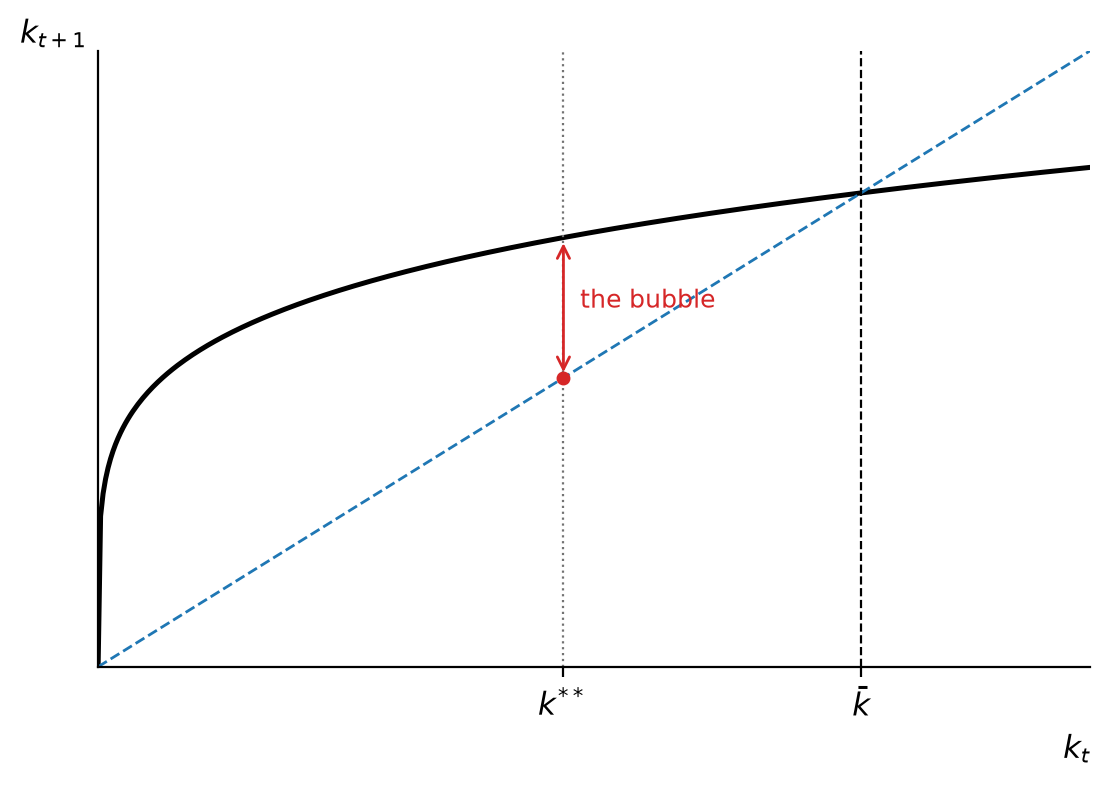

In [ ]:
alpha, beta, Xi = 0.20, 0.999**YEARS, 1.04**YEARS
fig, ax = plt.subplots()
bubbles.draw_tirole(ax, k_next, k_bar, k_golden, alpha, beta, Xi)
style.save(fig, "TiroleBubble")

In [ ]:
share = bubble(alpha, beta, Xi) / (beta / (1 + beta) * (1 - alpha) * k_golden(alpha, Xi - 1) ** alpha)
rate = interest_factor(k_bar(alpha, beta, Xi), alpha) ** (1 / YEARS) - 1
print(f"with no bubble: capital {k_bar(alpha, beta, Xi):.4f}, interest rate {rate:.2%} a year against population growth 4%")
print(f"with the bubble: capital {k_golden(alpha, Xi - 1):.4f} (the golden rule), the bubble {share:.0%} of the young's savings")
olg = (1 / 3, 0.96**YEARS, 1.01**YEARS)
print(f"at the OLG chapter's calibration the bubble would be {bubble(*olg):.3f}: negative, so none can last")

with no bubble: capital 0.0532, interest rate 3.18% a year against population growth 4%
with the bubble: capital 0.0325 (the golden rule), the bubble 33% of the young's savings
at the OLG chapter's calibration the bubble would be -0.864: negative, so none can last


## The chapter's results

In [ ]:
assert abs(1 / D - 20) < 1e-12 and abs(np.log(2) / -np.log(1 - D) - 13.51) < 0.01  # the chapter's numbers
assert abs(np.mean(life) - 20) < 0.5 and np.median(life) in (13, 14)
B = simulate(R, D, 60, bubbles=200_000, seed=3)
assert abs(B[10].mean() / R**10 - 1) < 0.02  # the bubble's expected value grows at R
assert k_bar(alpha, beta, Xi) > k_golden(alpha, Xi - 1) and bubble(alpha, beta, Xi) > 0  # inefficient: a bubble
assert bubble(*olg) < 0  # the OLG chapter's economy is efficient: no bubble

## With sliders

Each panel redraws on fixed axes, which hold every combination of its sliders' values, so what moves is the economy, not the scale.

Bubbles that burst: a higher chance of bursting makes a bubble grow faster while it lasts, and last less long.

In [ ]:
bubbles.sliders_bursting(simulate, expected, lifetimes)

Tirole's bubble: a bubble can last only when the economy without it is dynamically inefficient, its interest rate below the growth rate of the population. More patience, a lower capital share and faster population growth push it there.

In [ ]:
bubbles.sliders_tirole(k_next, k_bar, k_golden, interest_factor)